# 02 · Train and evaluate the linear regression model

**Goal:** predict clicks for an ad and measure how good those predictions are.

1. Split the data into training (80%) and test (20%) sets
2. Train three models: an average-only baseline, linear regression on raw clicks, and linear regression on log clicks
3. Compare them with RMSE, MAE and R²
4. Check the residuals (the errors) for patterns
5. Read the coefficients to see what the model learned

The same logic runs from the command line with `python src/train.py`, which also saves the final model.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT / 'src'))
from train import build_models, evaluate, load_dataset, SEED

## 1. Train/test split
The model never sees the test set during training, so test scores show how it will do on new ads.

In [2]:
X, y = load_dataset(ROOT / 'data' / 'youtube_ads.csv')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f'train: {len(X_train):,} rows   test: {len(X_test):,} rows')

train: 16,000 rows   test: 4,000 rows


## 2. Train three models

In [3]:
models = build_models()
preds, rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = np.clip(model.predict(X_test), 0, None)
    rows.append({'model': name, **evaluate(y_test, preds[name])})
results = pd.DataFrame(rows).set_index('model').round(3)
results

,rmse,mae,r2,median_abs_pct_error
model,,,,
baseline,625.858,391.934,-0.000,74.484
linear_raw,356.438,196.458,0.676,47.761
linear_log,139.087,71.632,0.951,12.203


### How to read these metrics
- **RMSE** (root mean squared error): typical error in clicks, punishing big misses more. Lower is better.
- **MAE** (mean absolute error): average miss in clicks. Lower is better.
- **R²**: share of the variation in clicks the model explains. 1.0 is perfect, 0 is no better than the average.
- **median_abs_pct_error**: for a typical ad, how far off the prediction is in percent.

The baseline has R² = 0, as expected. Linear regression on raw clicks explains about two thirds of the variation. Predicting **log clicks** explains about 95% and cuts the typical error to around 12%.

**Why does the log version win?** Clicks = impressions × CTR, and each feature *multiplies* the CTR. A linear model adds effects together, so it can't capture multiplication on the raw scale. Taking logs turns multiplication into addition: log(clicks) = log(impressions) + log(CTR effects). Now a linear model fits the data's true shape.

## 3. Actual vs predicted

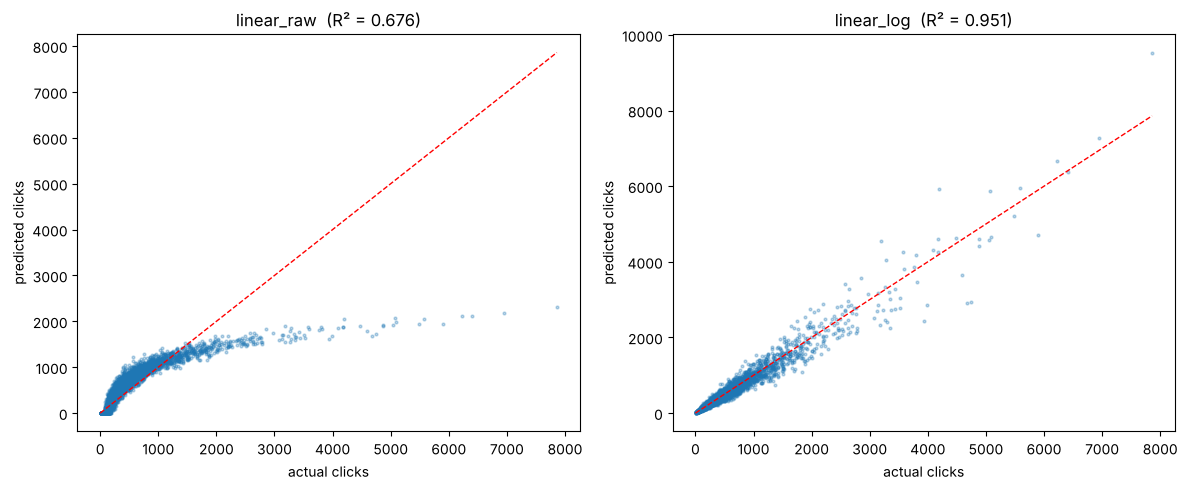

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['linear_raw', 'linear_log']):
    ax.scatter(y_test, preds[name], s=4, alpha=0.3)
    lim = [0, y_test.max()]
    ax.plot(lim, lim, 'r--', lw=1)
    ax.set(title=f'{name}  (R² = {results.loc[name, "r2"]:.3f})', xlabel='actual clicks', ylabel='predicted clicks')
plt.tight_layout(); plt.show()

Points on the red line are perfect predictions. The raw model fans out and even predicts negative clicks for small ads, which we clip to 0. The log model hugs the line across the whole range.

## 4. Residual analysis
Linear regression assumes the errors have no pattern: centred on zero, with the same spread everywhere. We check this on the scale the model was trained on.

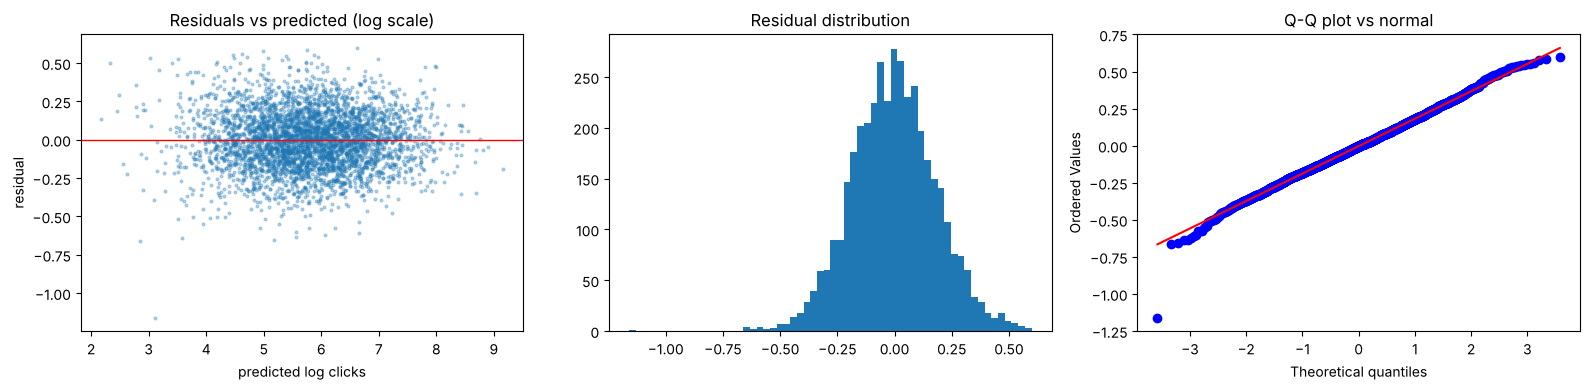

mean residual: -0.0030   std: 0.185


In [5]:
log_model = models['linear_log']
log_pred = np.log1p(log_model.predict(X_test))
log_true = np.log1p(y_test)
resid = log_true - log_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(log_pred, resid, s=4, alpha=0.3); axes[0].axhline(0, color='r', lw=1)
axes[0].set(title='Residuals vs predicted (log scale)', xlabel='predicted log clicks', ylabel='residual')
axes[1].hist(resid, bins=60); axes[1].set_title('Residual distribution')
import scipy.stats as st
st.probplot(resid, dist='norm', plot=axes[2]); axes[2].set_title('Q-Q plot vs normal')
plt.tight_layout(); plt.show()
print(f'mean residual: {resid.mean():.4f}   std: {resid.std():.3f}')

The residuals form a flat, even band around zero with a bell-shaped histogram, and the Q-Q plot is close to a straight line. So the model's assumptions hold well, and there's no obvious pattern left for a linear model to learn.

## 5. What did the model learn?
Because the model predicts log clicks, each coefficient converts to a **percentage effect on clicks**: `% change = (exp(coef) − 1) × 100`.

- For numeric features (scaled), it's the effect of a one standard deviation increase.
- For categories, it's the effect compared with the reference level that was dropped by one-hot encoding (Beauty, Desktop, Bumper, 18-24, afternoon).

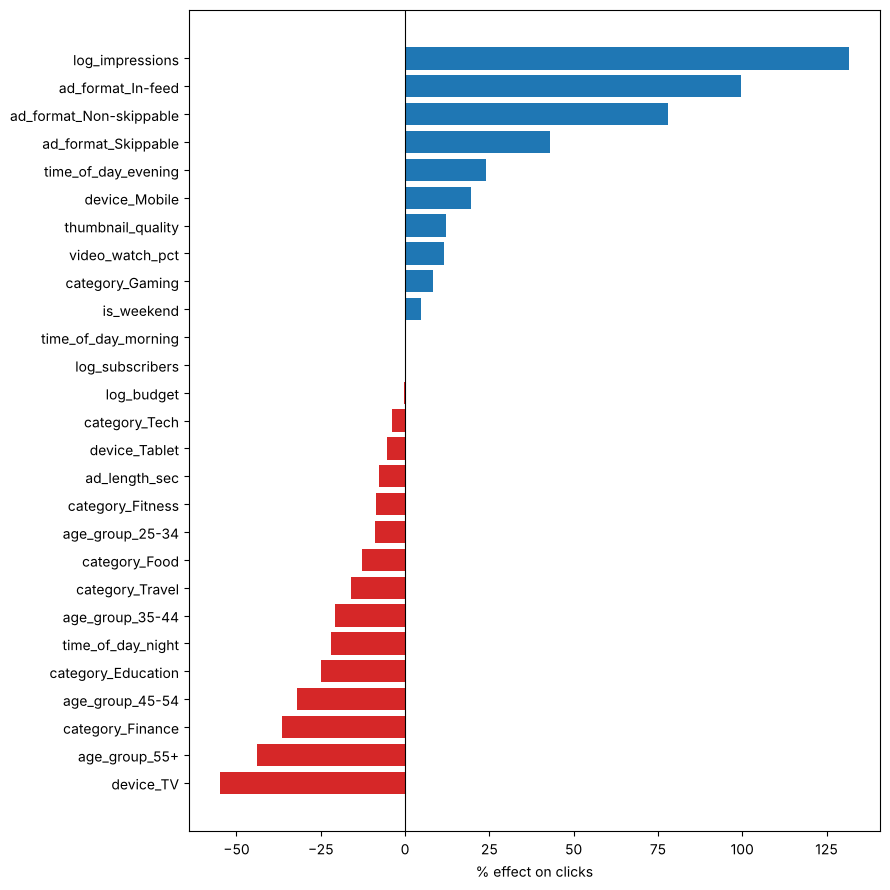

In [6]:
pipe = log_model.regressor_
names = pipe.named_steps['prep'].get_feature_names_out()
coefs = pipe.named_steps['model'].coef_
coef_df = pd.DataFrame({'feature': names, 'coef': coefs})
coef_df['pct_effect_on_clicks'] = (np.exp(coef_df['coef']) - 1) * 100
coef_df['feature'] = coef_df['feature'].str.replace('num__', '').str.replace('cat__', '')
coef_df = coef_df.sort_values('pct_effect_on_clicks')

fig, ax = plt.subplots(figsize=(9, 9))
colors = ['tab:red' if v < 0 else 'tab:blue' for v in coef_df['pct_effect_on_clicks']]
ax.barh(coef_df['feature'], coef_df['pct_effect_on_clicks'], color=colors)
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('% effect on clicks')
plt.tight_layout(); plt.show()

In [7]:
coef_df.set_index('feature').round(3)

,coef,pct_effect_on_clicks
feature,,
device_TV,-0.795,-54.828
age_group_55+,-0.580,-44.036
category_Finance,-0.456,-36.644
age_group_45-54,-0.388,-32.135
category_Education,-0.287,-24.915
time_of_day_night,-0.248,-21.969
age_group_35-44,-0.231,-20.633
category_Travel,-0.176,-16.137
category_Food,-0.135,-12.663


Things to notice:
- **log_impressions** is the biggest driver: one standard deviation more impressions more than doubles the clicks.
- **log_budget** ends up near zero, even though it was strongly correlated with clicks in Step 1. Budget only matters *because* it buys impressions, so once impressions are in the model, budget adds nothing new. This is multicollinearity in action, and it's why a single correlation can mislead.
- **TV** and **55+** audiences have the biggest negative effects, and **In-feed** and **Non-skippable** formats lift clicks compared with Bumper ads. This matches the patterns we found in Step 1.
- **log_subscribers** has a coefficient near zero, confirming Step 1: it doesn't help.

## 6. Is the score stable?
5-fold cross-validation trains and tests on five different splits. A small spread means the score isn't luck.

In [8]:
from sklearn.model_selection import KFold, cross_val_score
cv = cross_val_score(build_models()['linear_log'], X, y, cv=KFold(5, shuffle=True, random_state=SEED), scoring='r2')
print('R² per fold:', cv.round(3))
print(f'mean {cv.mean():.3f} ± {cv.std():.3f}')

R² per fold: [0.951 0.962 0.959 0.957 0.953]
mean 0.956 ± 0.004


## Summary
| Model | What it shows |
|---|---|
| Baseline | R² = 0. Guessing the average misses by about 390 clicks on average |
| Linear on raw clicks | R² ≈ 0.68. The right features, but the wrong shape |
| **Linear on log clicks** | **R² ≈ 0.95, typical error about 12%. Chosen model** |

**Limitations:**
- The data is synthetic, so real-world accuracy would be lower.
- Converting log predictions back with `expm1` slightly underestimates the average (retransformation bias). For budgeting totals, a smearing correction could be added.
- Linear regression can't learn interactions, such as mobile *and* evening, unless we add them as features.

**Next (Step 3):** serve the saved model (`models/model.joblib`) behind a FastAPI web service.